# 3. Watching the other: Tit-for-Tat and Distance

Examples of:

- **Tit-for-Tat**: concede as much as the other just conceded;
- **Distance**: cover a fraction $k$ of the gap with the other's offer;
- why these strategies resist exploitation, and why conceding fast costs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from carpool import *

## 3.1 Tit-for-Tat

My concession $=$ `coef` $\times$ the last concession of the other agent. At the second round the other has not conceded yet, so the agent makes a small **first step**.

**Exercise 1**  
Write a function `alice_tft(r, T, mine, theirs)` for Alice (`coef = 1`, first step 1 EUR):  
first offer 18 EUR, then she lowers her price by Bob's last concession.  
Bob follows a fixed script: he offers 4, 6, 7, 7, 7, ... EUR.  
Run the negotiation for 5 rounds ($T = 5$) and print the offers: do you find the table of the slide?

In [2]:
# Exercise 1: your code here

In [ ]:

res = negotiate(alice_tft, bob_scripted, T=5)
for r, (a, b) in enumerate(zip(res["alice"], res["bob"])):
    print(f"round {r + 1}: Bob offers {b} EUR, Alice asks {a} EUR")

round 1: Bob offers 4 EUR, Alice asks 18 EUR
round 2: Bob offers 6 EUR, Alice asks 17 EUR
round 3: Bob offers 7 EUR, Alice asks 15 EUR
round 4: Bob offers 7 EUR, Alice asks 14 EUR
round 5: Bob offers 7 EUR, Alice asks 14 EUR


**Reading.**  
Alice answers each concession of Bob, one round later: $+2$ then $-2$, $+1$ then $-1$.  
When Bob stops, Alice stops.  
The same function is in `carpool.py`: `tit_for_tat(mine, theirs, start, direction, coef, first_step)` (`direction = -1` for Alice who goes down, `+1` for Bob).

---

**Exercise 2**.  
Compare two Alices facing a **Boulware** Bob ($\beta = 0.3$): a linear Alice and a Tit-for-Tat Alice.  
Then make two Tit-for-Tat agents negotiate.   
Print prices and gains.

In [4]:
# Exercise 2: your code here

linear Alice vs Boulware Bob  : 8.58 EUR at round 7, gains [4.58 9.42]
TfT Alice vs Boulware Bob     : 12.20 EUR at round 8, gains [8.2 5.8]
TfT Alice vs TfT Bob          : 11.00 EUR at round 7, gains [7. 7.]


**Reading.**

- The linear Alice concedes whatever Bob does: the Boulware Bob pays only 8.6 EUR and takes most of the surplus.
- The Tit-for-Tat Alice only concedes when Bob concedes: a Boulware Bob, who concedes very little at the beginning, obtains very little. The price goes up to 12.2 EUR: Tit-for-Tat **cannot be exploited**.
- Two Tit-for-Tat agents concede 1 EUR each per round (their first steps) and meet in the middle: 11 EUR.

This is the **reciprocity** of Axelrod's repeated games.

---

## 3.2 Distance

$$p' = p + k\,(p_{\text{received}} - p)$$

At each round, the agent covers a fraction $k$ of the gap between its offer and the other's last offer.

**Exercise 3**.  
Make a Distance Alice ($k = 0.2$) negotiate with a Distance Bob ($k = 0.1$), with 30 rounds.  
Compare the price with the formula of the slide $p^* = \frac{k_2\, b_0 + k_1\, s_0}{k_1 + k_2}$ (buyer Bob: $b_0 = 4$, $k_1$; seller Alice: $s_0 = 18$, $k_2$).  
Then give the same $k = 0.2$ to both.

In [6]:
# Exercise 3: your code here

k_Alice=0.2, k_Bob=0.1: price 8.73 EUR (formula 8.67), round 10
k_Alice=0.2, k_Bob=0.2: price 11.00 EUR (formula 11.00), round 7


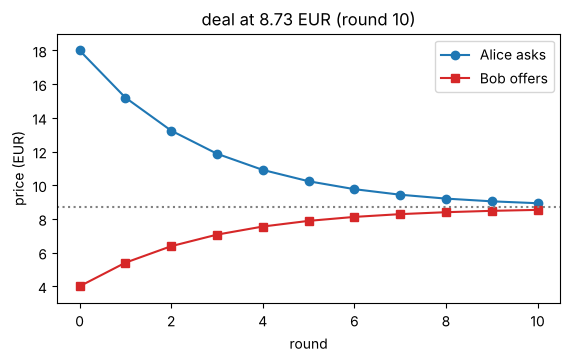

**Reading.**  
With $k = 0.2$ against $0.1$, Alice concedes twice as fast and pays for it: about **8.7 EUR** instead of 11 EUR.  
With the same $k$, the agents meet in the middle (11 EUR, the Nash solution).  
**Conceding fast costs**, like being impatient in Rubinstein's model.

---

**Exercise 4**.  
Bob keeps $k = 0.1$.  
Plot the price as a function of Alice's $k$ (from 0.05 to 0.5), from the simulation and from the formula.

In [8]:
# Exercise 4: your code here

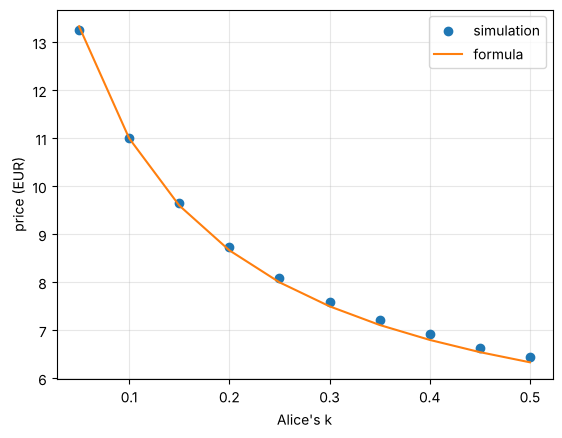

In [ ]:
ks = np.linspace(0.05, 0.5, 10)
#TODO: complete...

**Reading.**  
The faster Alice concedes, the lower the price.  
The simulation follows the formula (small differences come from the 0.5 EUR tolerance of the deal).

---

## Key points

| Strategy | Behaviour | Game theory |
|---|---|---|
| Tit-for-Tat | concedes as much as the other | reciprocity (Axelrod): cannot be exploited, needs a first step |
| Distance ($k$) | covers a fraction $k$ of the gap | conceding fast costs; same $k$ $\Rightarrow$ Nash (11 EUR) |